In [1]:
import pandas as pd

orders = pd.read_csv("../data/raw/orders.csv")

print("Dataset shape:", orders.shape)
print("\nColumns:")
print(orders.columns.tolist())

print("\nFirst 5 rows:")
print(orders.head())

Dataset shape: (10000, 9)

Columns:
['order_id', 'customer_id', 'restaurant_id', 'order_timestamp', 'order_amount', 'num_items', 'order_status', 'order_hour', 'order_date']

First 5 rows:
   order_id  customer_id  restaurant_id      order_timestamp  order_amount  \
0         1          485             10  2024-01-28 07:24:00       1748.55   
1         2          276             13  2025-10-22 18:26:00        912.87   
2         3           71             20  2024-01-15 01:04:00       1071.24   
3         4          183             77  2022-01-18 14:35:00        712.16   
4         5          122             44  2025-06-29 12:41:00         77.87   

   num_items order_status  order_hour  order_date  
0          6    Completed           7  2024-01-28  
1          9    Completed          18  2025-10-22  
2          2    Completed           1  2024-01-15  
3         10    Completed          14  2022-01-18  
4          4    Completed          12  2025-06-29  


In [2]:
# Convert order_timestamp to datetime
orders["order_timestamp"] = pd.to_datetime(orders["order_timestamp"])

# Group orders by hour
hourly_demand = (
    orders.set_index("order_timestamp")
    .resample("h")
    .size()
    .reset_index(name="order_count")
)

print("Hourly dataset shape:", hourly_demand.shape)
print(hourly_demand.head())

Hourly dataset shape: (35063, 2)
      order_timestamp  order_count
0 2022-01-01 00:00:00            1
1 2022-01-01 01:00:00            0
2 2022-01-01 02:00:00            0
3 2022-01-01 03:00:00            0
4 2022-01-01 04:00:00            0


In [3]:
print(hourly_demand["order_count"].describe())

print("\nTotal orders:", hourly_demand["order_count"].sum())
print("Hours with orders:", (hourly_demand["order_count"] > 0).sum())
print("Hours with zero orders:", (hourly_demand["order_count"] == 0).sum())

count    35063.000000
mean         0.285201
std          0.531855
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          5.000000
Name: order_count, dtype: float64

Total orders: 10000
Hours with orders: 8744
Hours with zero orders: 26319


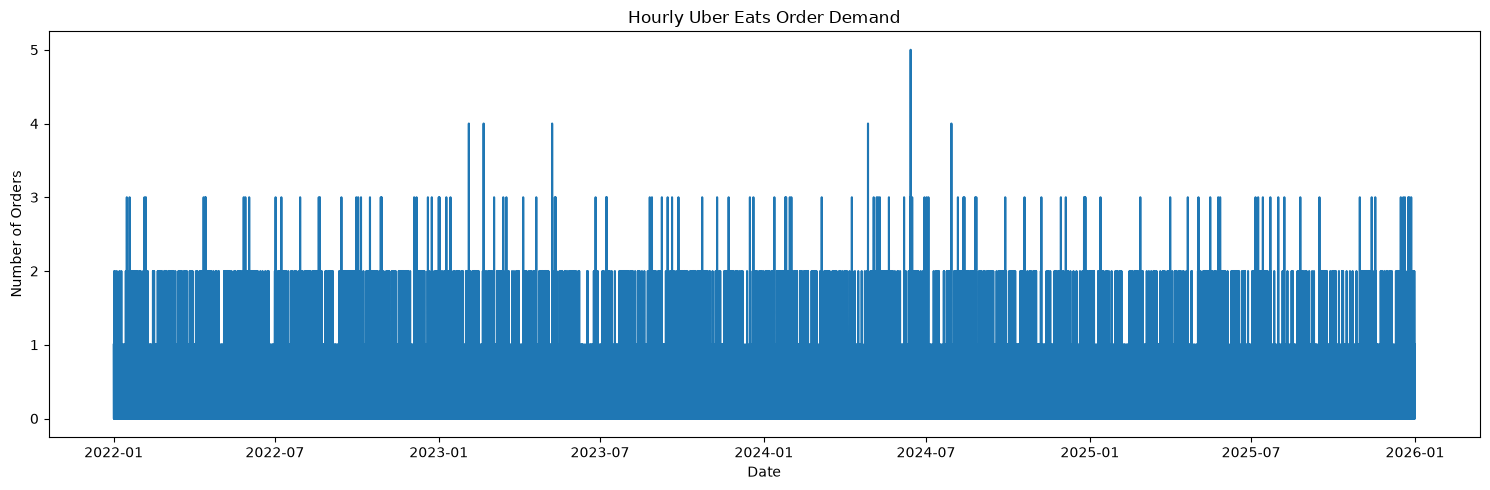

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
plt.plot(hourly_demand["order_timestamp"], hourly_demand["order_count"])
plt.title("Hourly Uber Eats Order Demand")
plt.xlabel("Date")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

/tmp/ipykernel_6942/1426365712.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  hourly_demand["day_of_week"] = hourly_demand["order_timestamp"].dt.dayofweek


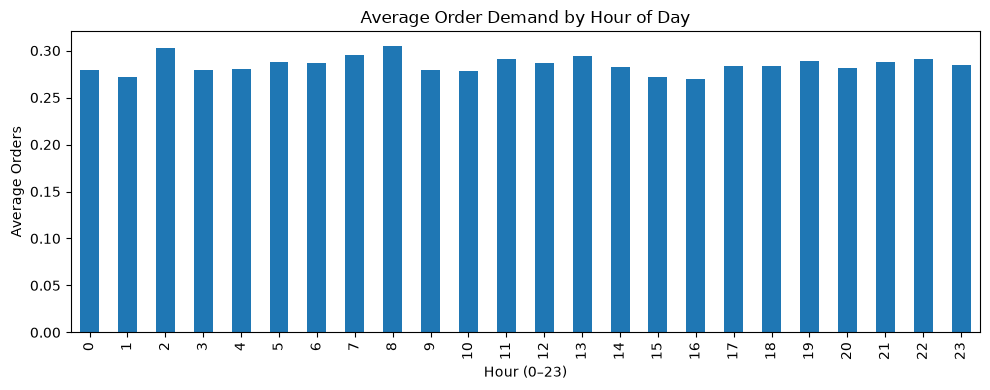

Average hourly orders:
is_weekend
Weekday    0.283768
Weekend    0.288776
Name: order_count, dtype: float64


In [5]:
# Extract date and hour information
hourly_demand["hour"] = hourly_demand["order_timestamp"].dt.hour
hourly_demand["day_of_week"] = hourly_demand["order_timestamp"].dt.dayofweek
hourly_demand["is_weekend"] = hourly_demand["day_of_week"] >= 5

# Average orders by hour of day
hourly_pattern = hourly_demand.groupby("hour")["order_count"].mean()

plt.figure(figsize=(10, 4))
hourly_pattern.plot(kind="bar")
plt.title("Average Order Demand by Hour of Day")
plt.xlabel("Hour (0–23)")
plt.ylabel("Average Orders")
plt.tight_layout()
plt.show()

# Compare weekdays and weekends
weekend_pattern = hourly_demand.groupby("is_weekend")["order_count"].mean()

print("Average hourly orders:")
print(weekend_pattern.rename(index={False: "Weekday", True: "Weekend"}))

In [6]:

# Total orders by hour of day
orders_by_hour = hourly_demand.groupby("hour")["order_count"].sum()

print("Top 5 busiest hours:")
print(orders_by_hour.sort_values(ascending=False).head())

# Total orders by day of week
orders_by_day = hourly_demand.groupby("day_of_week")["order_count"].sum()

orders_by_day.index = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

print("\nOrders by day of week:")
print(orders_by_day)

Top 5 busiest hours:
hour
8     446
2     442
7     432
13    430
11    426
Name: order_count, dtype: int64

Orders by day of week:
Monday       1377
Tuesday      1435
Wednesday    1429
Thursday     1409
Friday       1453
Saturday     1469
Sunday       1428
Name: order_count, dtype: int64


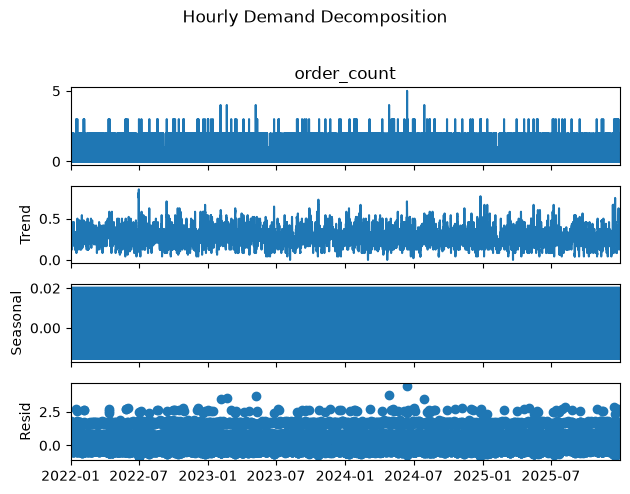

In [7]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Use the timestamp as the index
ts = hourly_demand.set_index("order_timestamp")["order_count"]

# Decompose demand using a 24-hour seasonal period
decomposition = seasonal_decompose(
    ts,
    model="additive",
    period=24
)

decomposition.plot()
plt.suptitle("Hourly Demand Decomposition", y=1.02)
plt.tight_layout()
plt.show()

In [8]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(ts)

print("ADF Statistic:", adf_result[0])
print("P-value:", adf_result[1])
print("Critical Values:", adf_result[4])

if adf_result[1] <= 0.05:
    print("Conclusion: The series is stationary.")
else:
    print("Conclusion: The series may be non-stationary.")

ADF Statistic: -187.64990291177895
P-value: 0.0
Critical Values: {'1%': np.float64(-3.430536520415736), '5%': np.float64(-2.861622437419146), '10%': np.float64(-2.5668138788464785)}
Conclusion: The series is stationary.


/tmp/ipykernel_6942/3030247623.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(ts)


In [9]:
# Sort the time series chronologically
ts = ts.sort_index()

# Split chronologically: first 80% for training, last 20% for testing
split_index = int(len(ts) * 0.8)

train = ts.iloc[:split_index]
test = ts.iloc[split_index:]

print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

print("\nTraining observations:", len(train))
print("Testing observations:", len(test))

Training period: 2022-01-01 00:00:00 to 2025-03-14 17:00:00
Testing period: 2025-03-14 18:00:00 to 2025-12-31 22:00:00

Training observations: 28050
Testing observations: 7013


In [10]:
from statsmodels.tsa.arima.model import ARIMA

# Train the ARIMA model
arima_model = ARIMA(train, order=(2, 0, 2))
arima_fit = arima_model.fit()

# Forecast the test period
arima_predictions = arima_fit.forecast(steps=len(test))

# Keep predictions non-negative for order counts
arima_predictions = arima_predictions.clip(lower=0)

print(arima_fit.summary())
print("\nFirst 10 forecasts:")
print(arima_predictions.head(10))

/home/nineleaps/Desktop/ML_Assignment/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/home/nineleaps/Desktop/ML_Assignment/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
/home/nineleaps/Desktop/ML_Assignment/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:            order_count   No. Observations:                28050
Model:                 ARIMA(2, 0, 2)   Log Likelihood              -22213.391
Date:                Thu, 29 Oct 2026   AIC                          44438.783
Time:                        11:32:48   BIC                          44488.233
Sample:                    01-01-2022   HQIC                         44454.701
                         - 03-14-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2884      0.005     56.418      0.000       0.278       0.298
ar.L1          0.2370      1.750      0.135      0.892      -3.193       3.667
ar.L2          0.1184      1.281      0.092      0.9

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

arima_mae = mean_absolute_error(test, arima_predictions)
arima_rmse = np.sqrt(mean_squared_error(test, arima_predictions))

print("ARIMA MAE:", round(arima_mae, 4))
print("ARIMA RMSE:", round(arima_rmse, 4))

ARIMA MAE: 0.4232
ARIMA RMSE: 0.5224


In [13]:
try:
    from prophet import Prophet
    print("Prophet is installed.")
except ImportError:
    print("Prophet is not installed.")

Importing plotly failed. Interactive plots will not work.


Prophet is installed.


In [14]:
from prophet import Prophet

prophet_data = hourly_demand[
    ["order_timestamp", "order_count"]
].copy()

prophet_data.columns = ["ds", "y"]

print(prophet_data.head())
print("\nDataset shape:", prophet_data.shape)

                   ds  y
0 2022-01-01 00:00:00  1
1 2022-01-01 01:00:00  0
2 2022-01-01 02:00:00  0
3 2022-01-01 03:00:00  0
4 2022-01-01 04:00:00  0

Dataset shape: (35063, 2)


In [15]:

# Prepare training data
prophet_train = prophet_data.iloc[:len(train)].copy()

# Train the model
prophet_model = Prophet(
    daily_seasonality=True,
    weekly_seasonality=True,
    yearly_seasonality=False
)

prophet_model.fit(prophet_train)

print("Prophet model trained successfully.")


11:48:50 - cmdstanpy - INFO - Chain [1] start processing
11:48:56 - cmdstanpy - INFO - Chain [1] done processing


Prophet model trained successfully.


In [16]:
# Create future dates for the test period
future = prophet_data.iloc[len(train):][["ds"]].copy()

# Generate forecasts
prophet_forecast = prophet_model.predict(future)

# Extract predictions
prophet_predictions = prophet_forecast["yhat"].values

# Prevent negative order predictions
prophet_predictions = prophet_predictions.clip(min=0)

print("First 10 Prophet predictions:")
print(prophet_predictions[:10])
print("\nTotal predictions:", len(prophet_predictions))

First 10 Prophet predictions:
[0.28413433 0.29465942 0.29642583 0.2900612  0.28313908 0.28240969
 0.28729146 0.29098836 0.28789128 0.27966171]

Total predictions: 7013


In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

prophet_mae = mean_absolute_error(test, prophet_predictions)
prophet_rmse = np.sqrt(mean_squared_error(test, prophet_predictions))

print("Prophet MAE:", round(prophet_mae, 4))
print("Prophet RMSE:", round(prophet_rmse, 4))

Prophet MAE: 0.4188
Prophet RMSE: 0.5224


In [18]:
model_comparison = pd.DataFrame({
    "Model": ["ARIMA", "Prophet"],
    "MAE": [arima_mae, prophet_mae],
    "RMSE": [arima_rmse, prophet_rmse]
})

print(model_comparison.round(4))

     Model     MAE    RMSE
0    ARIMA  0.4232  0.5224
1  Prophet  0.4188  0.5224


In [19]:
model_comparison.to_csv(
    "../data/processed/demand_forecast_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

Model comparison saved successfully.


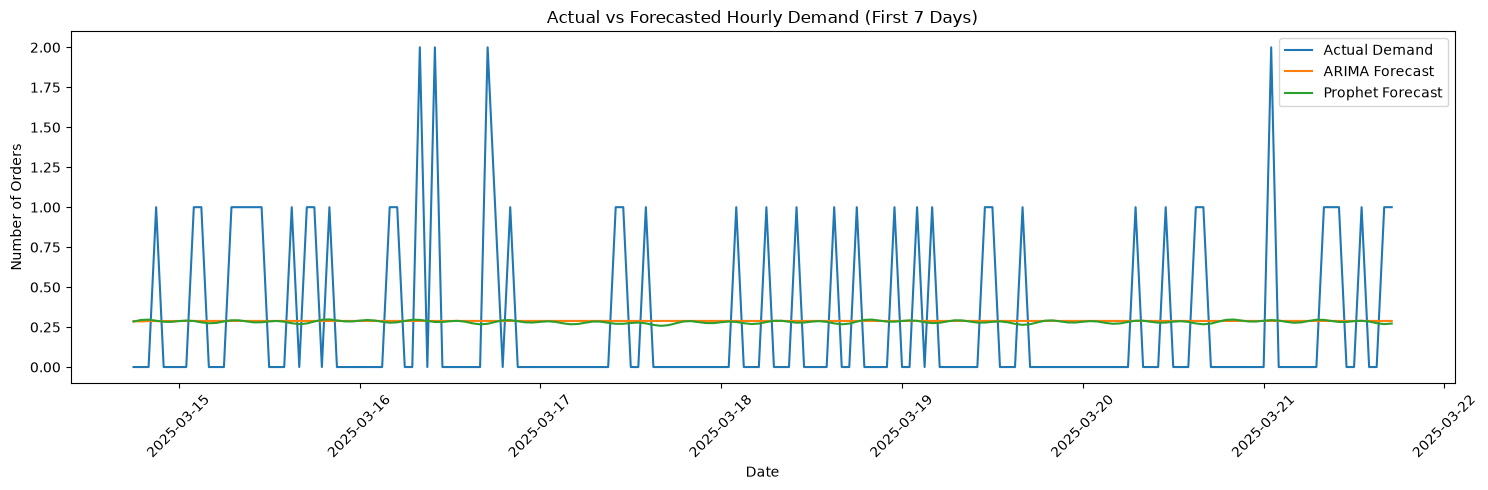

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(test.index[:168], test.values[:168],
         label="Actual Demand")

plt.plot(test.index[:168], arima_predictions[:168],
         label="ARIMA Forecast")

plt.plot(test.index[:168], prophet_predictions[:168],
         label="Prophet Forecast")

plt.title("Actual vs Forecasted Hourly Demand (First 7 Days)")
plt.xlabel("Date")
plt.ylabel("Number of Orders")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict the training average for every test hour
baseline_predictions = np.full(len(test), train.mean())

baseline_mae = mean_absolute_error(test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(test, baseline_predictions))

print("Baseline MAE:", round(baseline_mae, 4))
print("Baseline RMSE:", round(baseline_rmse, 4))

Baseline MAE: 0.4232
Baseline RMSE: 0.5224


In [22]:
model_comparison = pd.DataFrame({
    "Model": ["Baseline", "ARIMA", "Prophet"],
    "MAE": [baseline_mae, arima_mae, prophet_mae],
    "RMSE": [baseline_rmse, arima_rmse, prophet_rmse]
})

print(model_comparison.round(4))

      Model     MAE    RMSE
0  Baseline  0.4232  0.5224
1     ARIMA  0.4232  0.5224
2   Prophet  0.4188  0.5224


In [23]:
model_comparison.to_csv(
    "../data/processed/demand_forecast_model_comparison.csv",
    index=False
)

print("Final model comparison saved.")

Final model comparison saved.


In [24]:
# Save the hourly demand dataset
hourly_demand.to_csv(
    "../data/processed/hourly_demand.csv",
    index=False
)

print("Hourly demand dataset saved.")
print("Shape:", hourly_demand.shape)

Hourly demand dataset saved.
Shape: (35063, 5)


In [25]:
adf_summary = pd.DataFrame({
    "ADF Statistic": [adf_result[0]],
    "P-value": [adf_result[1]],
    "Critical Value (1%)": [adf_result[4]["1%"]],
    "Critical Value (5%)": [adf_result[4]["5%"]],
    "Critical Value (10%)": [adf_result[4]["10%"]]
})

print(adf_summary.round(4))

adf_summary.to_csv(
    "../data/processed/adf_test_results.csv",
    index=False
)

print("ADF results saved.")

   ADF Statistic  P-value  Critical Value (1%)  Critical Value (5%)  \
0      -187.6499      0.0              -3.4305              -2.8616   

   Critical Value (10%)  
0               -2.5668  
ADF results saved.


In [26]:
forecast_results = pd.DataFrame({
    "timestamp": test.index,
    "actual_orders": test.values,
    "baseline_forecast": baseline_predictions,
    "arima_forecast": arima_predictions,
    "prophet_forecast": prophet_predictions
})

forecast_results.to_csv(
    "../data/processed/final_hourly_demand_forecast.csv",
    index=False
)

print("Forecast results saved.")
print(forecast_results.head(10))

Forecast results saved.
                              timestamp  actual_orders  baseline_forecast  \
2025-03-14 18:00:00 2025-03-14 18:00:00              0           0.288414   
2025-03-14 19:00:00 2025-03-14 19:00:00              0           0.288414   
2025-03-14 20:00:00 2025-03-14 20:00:00              0           0.288414   
2025-03-14 21:00:00 2025-03-14 21:00:00              1           0.288414   
2025-03-14 22:00:00 2025-03-14 22:00:00              0           0.288414   
2025-03-14 23:00:00 2025-03-14 23:00:00              0           0.288414   
2025-03-15 00:00:00 2025-03-15 00:00:00              0           0.288414   
2025-03-15 01:00:00 2025-03-15 01:00:00              0           0.288414   
2025-03-15 02:00:00 2025-03-15 02:00:00              1           0.288414   
2025-03-15 03:00:00 2025-03-15 03:00:00              1           0.288414   

                     arima_forecast  prophet_forecast  
2025-03-14 18:00:00        0.287949          0.284134  
2025-03-14 19:00

In [27]:
hourly_demand[["order_timestamp", "order_count"]].to_csv(
    "../data/processed/hourly_demand.csv",
    index=False
)

print("Clean hourly demand dataset saved.")

Clean hourly demand dataset saved.
